In [1]:
import pandas as pd
from sklearn.model_selection   import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.multiclass        import OneVsRestClassifier
from sklearn.linear_model      import LogisticRegression
from sklearn.pipeline          import Pipeline
from sklearn.metrics           import classification_report, hamming_loss

# 1) Load your data
df = pd.read_csv("/Users/emine2/Documents/CLASSES/2025-SPRING/IS-577/project/leo_search_results.csv")
df = df.dropna(subset=["Summary"])  # drop posts without text

# 2) Define X and y
X = df["Summary"]
# list all your 0/1 columns:
label_cols  = [
    "WEATHER", "OCEAN", "LAND", "SAFETY", "WATER", "SNOW", "HEALTH", "TRANSPORTATION", 
    "DIEOFF", "EXTREME_TEMP", "FISH", "LAND_ANIMALS", "INFRASTRUCTURE", "SEA_ANIMALS", 
    "PLANTS", "FOODSECURITY", "BIRD", "RANGE_CHANGE", "SEASON_TIMING", "EXTREME_PRECIP", 
    "ECONOMICIMPACT", "RECREATION", "INVERTEBRATES", "CULTURALIMPACT", "FLOOD", "INSECT", 
    "AIR", "ENERGY", "PERMAFROST", "WILDFIRE", "EXTREME_WIND", "DEFORMITY", "ABUNDANCE", 
    "FISHERIES", "SANITATION", "BEHAVIOR", "EROSION", "LANDSLIDE", "POLLUTION", 
    "WATERSECURITY", "DROUGHT", "MICROBES", "VIRULENCE", "HARVEST_FAILURE", "AIRQUALITY", 
    "PETS", "AQUA_AG", "DISPLACEMENT", "LIVESTOCK", "PARASITE", "ALGAL_BLOOM", 
    "WATER_MANAGEMENT", "ONEHEALTH", "ZOONOTIC_FLU", "ROS", "INFESTATION", "ARACHNIDS", 
    "STORMSURGE", "GLACIER_CHANGE", "ATMOSPHERE", "GROUNDWATER", "TOURISM", 
    "COMMUNICATION", "DEBRIS", "TORNADO", "PARALYTIC_SP", "EARTHQUAKE", "FORESTRY", 
    "AQUACULTURE", "VOLCANO", "THUNDERSTORM", "FUNGI", "REPTILES", "COLD_BLOODS", 
    "CONFLICT", "CHEMICAL_CHANGE", "INJURY", "SEA_LEVEL_CHANGE", "ACUTE_ILLNESS", 
    "MENTAL_HEALTH", "BURIAL_SITE", "RABIES", "SINKHOLE", "ANTHRAX", "RESILIENCE", 
    "DISTEMPER", "RELOCATION", "TSUNAMI", "CWD", "CHRONIC_ILLNESS", "TULAREMIA", 
    "VIBRIO", "UNUSUAL_VARIATION", "AMNESIC_SP", "TRICHINOSIS", "TOXOPLASMOSIS", 
    "RADIATION", "OTHER", "BOTULISM", "ALASKAPOX", "BRUCELLOSIS", "CORONAVIRUS", 
    "ANISAKID", "QFEVER", "OTHER_EVENT", "GIARDIASIS", "SMELL_TASTE", "DIPHTHERIA", 
    "MONKEYPOX"
]
y = df[label_cols].astype(int)

# 3) Train/test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# 4) Build a pipeline: TF-IDF → One-vs-Rest Logistic Regression
pipeline = Pipeline([
    ("tfidf", TfidfVectorizer(
        lowercase=True,
        stop_words="english",
        max_df=0.9,
        min_df=3
    )),
    ("clf", OneVsRestClassifier(
        LogisticRegression(solver="liblinear"),
        n_jobs=-1
    ))
])

# 5) Fit
pipeline.fit(X_train, y_train)

# 6) Predict on hold-out set
y_pred = pipeline.predict(X_test)

# 7) Evaluate
print("Hamming loss:", hamming_loss(y_test, y_pred))
print(classification_report(
    y_test, y_pred,
    target_names=label_cols,
    zero_division=0
))

Hamming loss: 0.022809857888109374
                   precision    recall  f1-score   support

          WEATHER       1.00      0.14      0.25        35
            OCEAN       1.00      0.12      0.21        25
             LAND       0.60      0.11      0.19        27
           SAFETY       0.00      0.00      0.00        15
            WATER       0.71      0.13      0.22        38
             SNOW       1.00      0.11      0.21        35
           HEALTH       0.00      0.00      0.00        11
   TRANSPORTATION       0.00      0.00      0.00        13
           DIEOFF       0.00      0.00      0.00        19
     EXTREME_TEMP       0.00      0.00      0.00         7
             FISH       1.00      0.17      0.29        29
     LAND_ANIMALS       0.00      0.00      0.00        14
   INFRASTRUCTURE       0.00      0.00      0.00        16
      SEA_ANIMALS       0.00      0.00      0.00        13
           PLANTS       0.82      0.22      0.35        41
     FOODSECURITY   

/Users/emine2/Documents/CLASSES/2025-SPRING/IS-577/project/is577/lib/python3.9/site-packages/sklearn/multiclass.py:90: UserWarning: Label not 61 is present in all training examples.
  warnings.warn(
/Users/emine2/Documents/CLASSES/2025-SPRING/IS-577/project/is577/lib/python3.9/site-packages/sklearn/multiclass.py:90: UserWarning: Label not 64 is present in all training examples.
  warnings.warn(
/Users/emine2/Documents/CLASSES/2025-SPRING/IS-577/project/is577/lib/python3.9/site-packages/sklearn/multiclass.py:90: UserWarning: Label not 76 is present in all training examples.
  warnings.warn(
/Users/emine2/Documents/CLASSES/2025-SPRING/IS-577/project/is577/lib/python3.9/site-packages/sklearn/multiclass.py:90: UserWarning: Label not 74 is present in all training examples.
  warnings.warn(
/Users/emine2/Documents/CLASSES/2025-SPRING/IS-577/project/is577/lib/python3.9/site-packages/sklearn/multiclass.py:90: UserWarning: Label not 78 is present in all training examples.
  warnings.warn(
/User

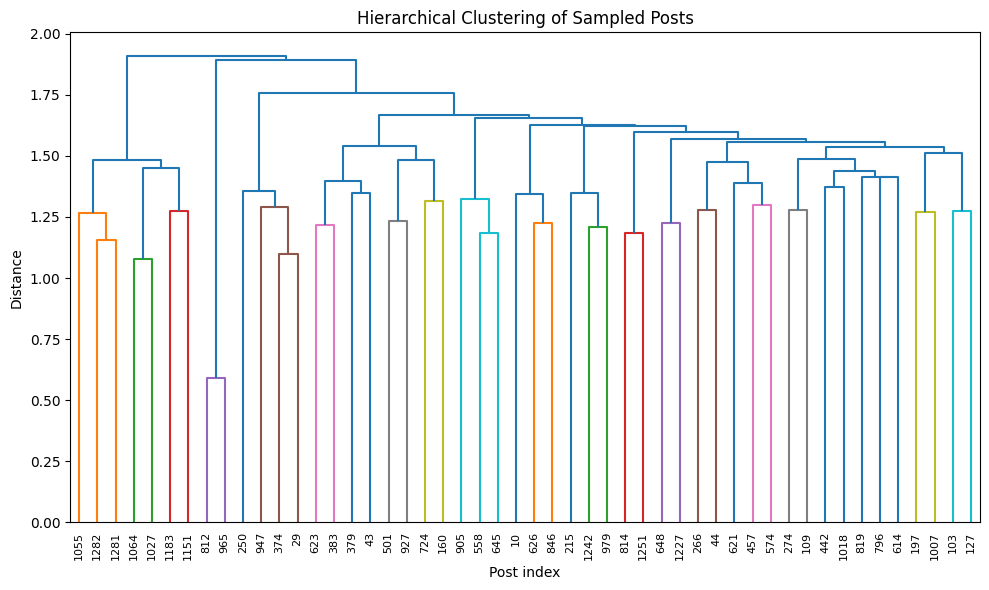

In [2]:
import numpy as np
from scipy.cluster.hierarchy import linkage, dendrogram
import matplotlib.pyplot as plt

# 1) Transform a small sample of summaries:
sample_idx = np.random.choice(len(X_test), size=50, replace=False)
docs = X_test.iloc[sample_idx]
tfidf = pipeline.named_steps["tfidf"]
X_sample = tfidf.transform(docs).toarray()

# 2) Compute linkage (Ward’s method on Euclidean dist of TF-IDF)
Z = linkage(X_sample, method="ward")

# 3) Plot
plt.figure(figsize=(10, 6))
dendrogram(Z, labels=docs.index.astype(str).tolist(), leaf_rotation=90)
plt.title("Hierarchical Clustering of Sampled Posts")
plt.xlabel("Post index")
plt.ylabel("Distance")
plt.tight_layout()
plt.show()

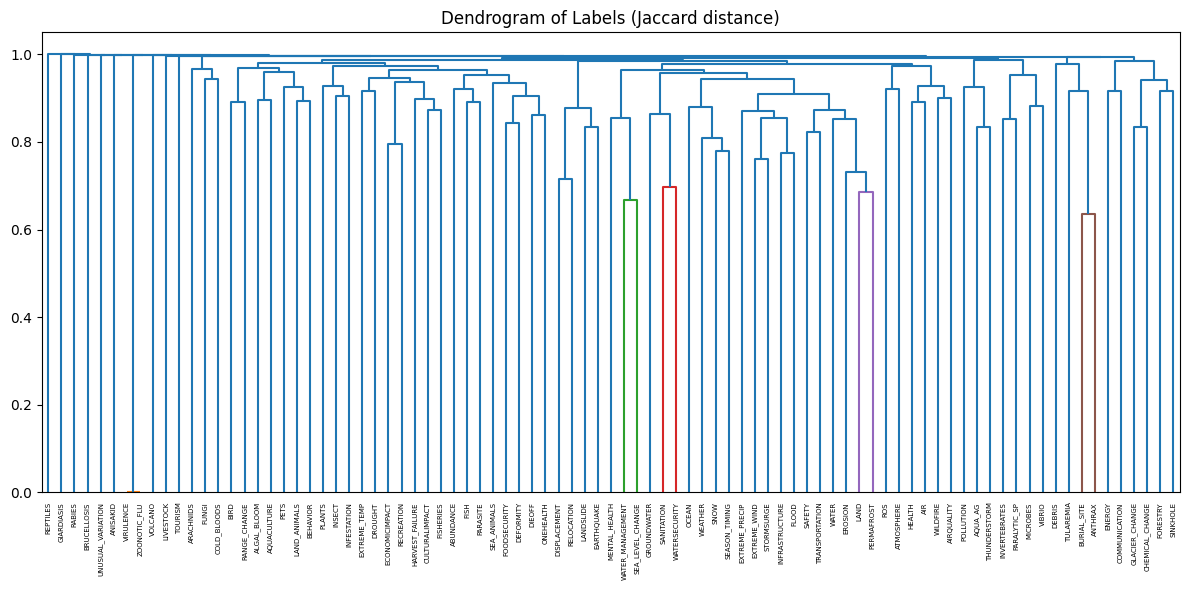

In [5]:
from sklearn.metrics import pairwise_distances
from scipy.cluster import hierarchy as sch
import matplotlib.pyplot as plt
from scipy.spatial.distance import squareform

# 1) keep only labels that occur
y2 = y.loc[:, y.sum(axis=0) > 0]

# 2) convert to a boolean NumPy array (shape: n_labels × n_posts)
M = y2.T.to_numpy().astype(bool)

# 3) compute pairwise Jaccard distance between each pair of label-vectors
dist_mat = pairwise_distances(M, metric="jaccard")

# 4) turn into condensed form
dist_vec = squareform(dist_mat)

# 5) linkage + plot
link = sch.linkage(dist_vec, method="average")
plt.figure(figsize=(12,6))
sch.dendrogram(link, labels=y2.columns.tolist(), leaf_rotation=90)
plt.title("Dendrogram of Labels (Jaccard distance)")
plt.tight_layout()
plt.show()